In [1]:
import json, subprocess, sys
from pathlib import Path

import matplotlib.pyplot as plt
import ollama
import pandas as pd
import psutil

print(sys.executable)  # should point inside your .venv folder

MODELS = ["llama3.2:1b", "qwen2.5:1.5b", "llama3.2:3b", "qwen2.5:3b"]
OPTS = {"temperature": 0, "num_ctx": 2048}
CACHE = Path("results/benchmark.jsonl")
CACHE.parent.mkdir(exist_ok=True)

d:\Projects\local-llm-comparisons\.venv\Scripts\python.exe


In [2]:
def ollama_mem_gb():
    """Approximate RAM used by Ollama processes right now."""
    total = 0
    for p in psutil.process_iter(["name", "memory_info"]):
        if (p.info["name"] or "").lower().startswith("ollama"):
            total += p.info["memory_info"].rss
    return total / 1e9

def rate(n, ns):
    return n / (ns / 1e9) if ns else float("nan")

def run(model, prompt, num_predict=120):
    r = ollama.chat(
        model=model,
        messages=[{"role": "user", "content": prompt}],
        options={**OPTS, "num_predict": num_predict},
    )
    return {
        "model": model,
        "text": r.message.content,
        "gen_tokens": r.eval_count,
        "prompt_tokens": r.prompt_eval_count,
        "gen_tok_s": rate(r.eval_count, r.eval_duration),
        "prompt_tok_s": rate(r.prompt_eval_count, r.prompt_eval_duration),
        "load_s": r.load_duration / 1e9,
        "total_s": r.total_duration / 1e9,
        "ram_gb": ollama_mem_gb(),
    }

def parse_json(t):
    t = t.strip()
    if t.startswith("```"):
        t = t.strip("`").strip()
        if t.lower().startswith("json"):
            t = t[4:]
    try:
        return json.loads(t)
    except Exception:
        return None

def score(item, text):
    t, low = text.strip(), text.strip().lower()
    kind, arg = item["check"]
    if kind == "contains":
        return int(any(a in low for a in arg))
    if kind == "starts":
        return int(low.startswith(arg))
    if kind == "exact":
        return int(t.strip(".! ") == arg)
    if kind == "words":
        return int(len(t.split()) == arg)
    if kind == "json_keys":
        o = parse_json(t)
        return int(isinstance(o, dict) and all(k in o for k in arg))
    if kind == "json_list_len":
        o = parse_json(t)
        return int(isinstance(o, list) and len(o) == arg)
    return 0

In [3]:
PROMPTS = [
 # factual
 {"id":"f1","cat":"factual","prompt":"What is the capital of Australia? Answer in one word.","check":("contains",["canberra"])},
 {"id":"f2","cat":"factual","prompt":"Which planet is known as the Red Planet? Answer in one word.","check":("contains",["mars"])},
 {"id":"f3","cat":"factual","prompt":"How many days are in a leap year? Reply with only the number.","check":("contains",["366"])},
 {"id":"f4","cat":"factual","prompt":"Who wrote the play Romeo and Juliet? Reply with only the surname.","check":("contains",["shakespeare"])},
 {"id":"f5","cat":"factual","prompt":"What is the largest ocean on Earth? Answer in one word.","check":("contains",["pacific"])},
 # arithmetic
 {"id":"a1","cat":"arithmetic","prompt":"What is 17 * 24? Reply with only the number.","check":("contains",["408"])},
 {"id":"a2","cat":"arithmetic","prompt":"What is 156 + 289? Reply with only the number.","check":("contains",["445"])},
 {"id":"a3","cat":"arithmetic","prompt":"What is 1000 - 387? Reply with only the number.","check":("contains",["613"])},
 {"id":"a4","cat":"arithmetic","prompt":"Pens cost 12 rupees each. How much do 7 pens cost? Reply with only the number.","check":("contains",["84"])},
 {"id":"a5","cat":"arithmetic","prompt":"What is 15% of 200? Reply with only the number.","check":("contains",["30"])},
 # format following
 {"id":"j1","cat":"format","prompt":'Reply with only a JSON object with the key "answer" and the value 5.',"check":("json_keys",["answer"])},
 {"id":"j2","cat":"format","prompt":"Reply with only a JSON list of the three primary colours as lowercase strings.","check":("json_list_len",3)},
 {"id":"j3","cat":"format","prompt":"Reply with exactly three words, no punctuation, describing the sea.","check":("words",3)},
 {"id":"j4","cat":"format","prompt":"Reply with only the word YES in capital letters.","check":("exact","YES")},
 {"id":"j5","cat":"format","prompt":'Reply with only a JSON object with keys "name" (string) and "age" (integer) for a fictional person.',"check":("json_keys",["name","age"])},
 # classification (last two are Bengali headlines)
 {"id":"c1","cat":"classification","prompt":"Is this review positive or negative? 'The battery died in a day.' One word.","check":("contains",["negative"])},
 {"id":"c2","cat":"classification","prompt":"Is this review positive or negative? 'Absolutely loved the service, will come again.' One word.","check":("contains",["positive"])},
 {"id":"c3","cat":"classification","prompt":"Classify this headline as sports, politics, or technology. One word. 'Parliament passes new budget after long debate'","check":("contains",["politics"])},
 {"id":"c4","cat":"classification","prompt":"Classify this Bengali headline as sports, politics, or technology. Answer in one English word. 'ভারত বনাম অস্ট্রেলিয়া ম্যাচে বিরাট কোহলির সেঞ্চুরি'","check":("contains",["sports"])},
 {"id":"c5","cat":"classification","prompt":"Classify this Bengali headline as sports, politics, or technology. Answer in one English word. 'সংসদে নতুন বাজেট পাস হয়েছে'","check":("contains",["politics"])},
 # reasoning / instructions
 {"id":"r1","cat":"reasoning","prompt":"Alice is taller than Bob. Bob is taller than Carol. Who is the shortest? One word.","check":("contains",["carol"])},
 {"id":"r2","cat":"reasoning","prompt":"If today is Monday, what day will it be in 3 days? One word.","check":("contains",["thursday"])},
 {"id":"r3","cat":"reasoning","prompt":"Which word does not belong: apple, banana, carrot, mango? One word.","check":("contains",["carrot"])},
 {"id":"r4","cat":"reasoning","prompt":"Reverse the word 'stone'. Reply with only the reversed word.","check":("contains",["enots"])},
 {"id":"r5","cat":"reasoning","prompt":"A purchase order is created by user U1, and its payment is processed by the same user U1. Is this a segregation-of-duties problem? Answer YES or NO first, then one short reason.","check":("starts","yes")},
]

GEN_PROMPT = "Explain in about 100 words what a database index is and why it speeds up queries."
LONG_TEXT = ("A purchase order is a document that a buyer sends to a supplier to confirm an order for goods or services. "
 "It lists the items, quantities, agreed prices and delivery dates. In most companies the process has several steps: "
 "an employee raises a purchase request, a manager approves it, the purchasing team creates the purchase order, "
 "the goods are received and checked, and finally the finance team pays the supplier's invoice. Each step is normally "
 "done by a different person so that no single individual can create, approve and pay for an order alone, "
 "which reduces the risk of error and fraud. ") * 2
print(len(PROMPTS), "scored prompts")

25 scored prompts


In [4]:
out = run("llama3.2:1b", PROMPTS[0]["prompt"])
print(out["text"], "|", round(out["gen_tok_s"], 1), "tok/s | RAM", round(out["ram_gb"], 2), "GB")
print(score(PROMPTS[0], out["text"]))

Canberra. | 14.5 tok/s | RAM 0.05 GB
1


In [5]:
def log(rec):
    with CACHE.open("a", encoding="utf-8") as f:
        f.write(json.dumps(rec) + "\n")

def already_done():
    if not CACHE.exists():
        return set()
    rows = map(json.loads, CACHE.read_text(encoding="utf-8").splitlines())
    return {(j["model"], j["id"], j["rep"]) for j in rows}

def stop(model):
    subprocess.run(["ollama", "stop", model], capture_output=True)

done = already_done()
for model in MODELS:
    print("=====", model)
    run(model, "Say hi.", 5)  # warm-up, not logged

    jobs = [(p["id"], p["cat"], 0, p["prompt"], 120, p) for p in PROMPTS]
    for rep in range(3):
        jobs.append(("speed_gen", "speed", rep, GEN_PROMPT, 120, None))
        # rep number at the start of the prompt stops Ollama reusing its cached prefix
        jobs.append(("speed_prompt", "speed", rep, f"[{rep}] Summarize in one sentence:\n{LONG_TEXT}", 20, None))

    for jid, cat, rep, prompt, npred, item in jobs:
        if (model, jid, rep) in done:
            continue
        out = run(model, prompt, npred)
        out.update(id=jid, cat=cat, rep=rep, correct=score(item, out["text"]) if item else None)
        log(out)
        print(f"{model:14s} {jid:13s} {out['gen_tok_s']:6.1f} tok/s")

    stop(model)  # unload so two models never sit in your 8 GB at once

===== llama3.2:1b
llama3.2:1b    f1              12.2 tok/s
llama3.2:1b    f2              10.1 tok/s
llama3.2:1b    f3              21.4 tok/s
llama3.2:1b    f4              17.0 tok/s
llama3.2:1b    f5              21.0 tok/s
llama3.2:1b    a1              19.1 tok/s
llama3.2:1b    a2              17.9 tok/s
llama3.2:1b    a3              16.5 tok/s
llama3.2:1b    a4              21.9 tok/s
llama3.2:1b    a5              21.8 tok/s
llama3.2:1b    j1              10.5 tok/s
llama3.2:1b    j2               8.9 tok/s
llama3.2:1b    j3              14.0 tok/s
llama3.2:1b    j4              22.3 tok/s
llama3.2:1b    j5               9.6 tok/s
llama3.2:1b    c1              16.2 tok/s
llama3.2:1b    c2              11.0 tok/s
llama3.2:1b    c3               9.1 tok/s
llama3.2:1b    c4              21.5 tok/s
llama3.2:1b    c5              16.8 tok/s
llama3.2:1b    r1              13.7 tok/s
llama3.2:1b    r2              12.1 tok/s
llama3.2:1b    r3               9.3 tok/s
llama3.2:1b    r

In [6]:
df = pd.DataFrame(map(json.loads, CACHE.read_text(encoding="utf-8").splitlines()))
scored = df[df.cat != "speed"]

summary = pd.DataFrame({
    "gen_tok_s":    df[df.id == "speed_gen"].groupby("model").gen_tok_s.mean(),
    "prompt_tok_s": df[df.id == "speed_prompt"].groupby("model").prompt_tok_s.mean(),
    "max_ram_gb":   df.groupby("model").ram_gb.max(),
    "accuracy_pct": scored.groupby("model").correct.mean() * 100,
}).round(2).loc[MODELS]
display(summary)

by_cat = (scored.pivot_table(index="model", columns="cat", values="correct", aggfunc="mean") * 100).round(0).loc[MODELS]
display(by_cat)

,gen_tok_s,prompt_tok_s,max_ram_gb,accuracy_pct
model,,,,
llama3.2:1b,10.04,23.71,0.05,76.0
qwen2.5:1.5b,10.90,32.15,0.05,96.0
llama3.2:3b,5.72,15.51,0.05,100.0
qwen2.5:3b,5.83,15.26,0.05,92.0


cat,arithmetic,classification,factual,format,reasoning
model,,,,,
llama3.2:1b,60.0,80.0,100.0,80.0,60.0
qwen2.5:1.5b,100.0,100.0,100.0,100.0,80.0
llama3.2:3b,100.0,100.0,100.0,100.0,100.0
qwen2.5:3b,100.0,100.0,100.0,100.0,60.0


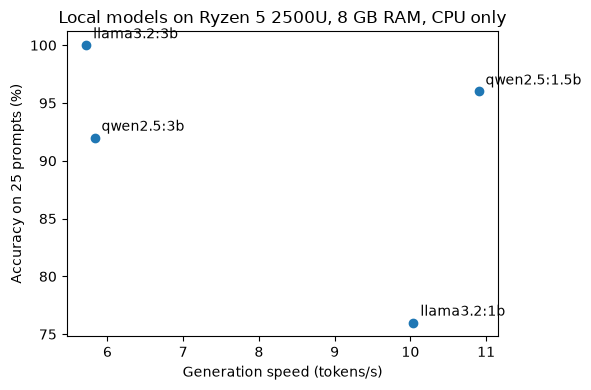

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(summary.gen_tok_s, summary.accuracy_pct)
for m, r in summary.iterrows():
    ax.annotate(m, (r.gen_tok_s, r.accuracy_pct), textcoords="offset points", xytext=(5, 5))
ax.set_xlabel("Generation speed (tokens/s)")
ax.set_ylabel("Accuracy on 25 prompts (%)")
ax.set_title("Local models on Ryzen 5 2500U, 8 GB RAM, CPU only")
fig.tight_layout()
fig.savefig("results/speed_vs_accuracy.png", dpi=150)

In [8]:
cold = {}
for m in MODELS:
    stop(m)
    cold[m] = round(run(m, "Say hi.", 5)["load_s"], 1)
    stop(m)
print(cold)

{'llama3.2:1b': 4.5, 'qwen2.5:1.5b': 4.2, 'llama3.2:3b': 8.0, 'qwen2.5:3b': 7.4}


## Findings

**Setup.** All models were run through Ollama on an AMD Ryzen 5 2500U laptop (4 cores / 8 threads, 8 GB RAM, single-channel DDR4-2400, Windows). The integrated Vega 8 GPU is not used by Ollama, so everything ran on the CPU. Settings: temperature 0, `num_ctx` 2048, outputs capped at 120 tokens. Speed numbers are means of 3 runs after a warm-up call. Accuracy comes from 25 short prompts (factual, arithmetic, format following, classification, reasoning), each run once and scored automatically.

| model | gen tok/s | prompt tok/s | accuracy (%) | cold load (s) |
|---|---|---|---|---|
| llama3.2:1b | 10.04 | 23.71 | 76 | 4.5 |
| qwen2.5:1.5b | 10.90 | 32.15 | 96 | 4.2 |
| llama3.2:3b | 5.72 | 15.51 | 100 | 8.0 |
| qwen2.5:3b | 5.83 | 15.26 | 92 | 7.4 |

Accuracy by category (%):

| model | arithmetic | classification | factual | format | reasoning |
|---|---|---|---|---|---|
| llama3.2:1b | 60 | 80 | 100 | 80 | 60 |
| qwen2.5:1.5b | 100 | 100 | 100 | 100 | 80 |
| llama3.2:3b | 100 | 100 | 100 | 100 | 100 |
| qwen2.5:3b | 100 | 100 | 100 | 100 | 60 |

![Speed vs accuracy](results/speed_vs_accuracy.png)

**What I saw.**
- Model size sets speed on this machine: the 1B-class models generate about 10-11 tokens/s and the 3B models about 5.7-5.8 tokens/s, so going from 1.5B to 3B roughly halves the speed.
- llama3.2:3b was the most accurate (100%) but also the slowest, while llama3.2:1b was fast but clearly the weakest (76%), with most of its misses in arithmetic and reasoning.
- qwen2.5:1.5b gave the best trade-off in this test: 96% accuracy at about 10.9 tokens/s, roughly 1.9x the generation speed of the 3B models.
- qwen2.5:3b scored below qwen2.5:1.5b (92% vs 96%), but that is a one-prompt difference on 25 prompts, so I do not read it as a real ranking.
- Cold load takes about 4-8 seconds depending on model size, and a 60-token answer takes roughly 6-10 seconds, which is usable for interactive demos but slow for batch work such as scoring hundreds of records.

**Memory.** My `psutil` readout (~0.05 GB for every model) was clearly wrong, because it only captured a small Ollama process and not the model runner, so I do not report it. As a reference, `ollama ps` showed llama3.2:3b using 2.6 GB when loaded (context 4096). Others from `ollama ps`: llama3.2:1b = <add>, qwen2.5:1.5b = <add>, qwen2.5:3b =